In [ ]:
# ============================================================
# SETUP
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import statsmodels.api as sm
import lightgbm as lgb
import json, pickle
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/siap'

freq_test = pd.read_csv(f'{BASE}/data/freq_test_v2.csv')
sev_full  = pd.read_csv(f'{BASE}/data/sev_full_v2.csv')

with open(f'{BASE}/data/feature_cols_v2.json') as f:
    X_cols = json.load(f)
with open(f'{BASE}/models/glm_columns.json') as f:
    glm_cols = json.load(f)

with open(f'{BASE}/models/glm_freq.pkl', 'rb') as f: glm_freq = pickle.load(f)
with open(f'{BASE}/models/glm_sev.pkl',  'rb') as f: glm_sev  = pickle.load(f)
with open(f'{BASE}/models/lgb_freq.pkl', 'rb') as f: lgb_freq_final = pickle.load(f)
with open(f'{BASE}/models/lgb_sev.pkl',  'rb') as f: lgb_sev_final  = pickle.load(f)

print(f"Test fréquence : {freq_test.shape}")
print(f"Sev full       : {sev_full.shape}")

Mounted at /content/drive
Test fréquence : (132882, 46)
Sev full       : (26340, 46)


In [ ]:
# ============================================================
# BLOC 1 — RECALCUL DU FACTEUR DE CORRECTION LIGHTGBM SÉVÉRITÉ
# ============================================================
# Le facteur (≈1.0202) calculé au script 4 n'a pas été sauvegardé.
# On le recalcule à l'identique : même split (random_state=42,
# test_size=0.2) sur sev_full pour retrouver X_sev_tr/y_sev_tr.

from sklearn.model_selection import train_test_split

X_sev_all = sev_full[X_cols].astype(float)
y_sev_all = sev_full['ClaimAmount'].values

X_sev_tr, _, y_sev_tr, _ = train_test_split(
    X_sev_all, y_sev_all, test_size=0.2, random_state=42
)

pred_lgb_sev_train = lgb_sev_final.predict(X_sev_tr)
correction_lgb_sev = y_sev_tr.mean() / pred_lgb_sev_train.mean()
print(f"Facteur de correction LightGBM sévérité : {correction_lgb_sev:.4f}")
# À l'avenir : sauvegarder ce facteur en JSON au script 4
# pour éviter de devoir le recalculer

Facteur de correction LightGBM sévérité : 1.0202


In [ ]:
# ============================================================
# BLOC 2 — PRÉDICTIONS DE FRÉQUENCE SUR LE TEST
# ============================================================
X_test = freq_test[X_cols].astype(float)
exposure_test = freq_test['Exposure'].values
y_test = freq_test['ClaimNb'].values

# GLM Poisson — attention à l'ordre EXACT des colonnes (glm_cols)
X_test_sm = sm.add_constant(X_test, has_constant='add')
X_test_sm = X_test_sm.reindex(columns=glm_cols)

pred_freq_glm = glm_freq.predict(X_test_sm, offset=np.log(exposure_test))

# LightGBM — offset via init_score à rajouter manuellement
raw_lgb = lgb_freq_final.predict(X_test, raw_score=True)
pred_freq_lgb = np.exp(raw_lgb + np.log(exposure_test))

print(f"Fréquence observée         : {y_test.sum()/exposure_test.sum():.4f}")
print(f"Fréquence prédite GLM      : {pred_freq_glm.sum()/exposure_test.sum():.4f}")
print(f"Fréquence prédite LightGBM : {pred_freq_lgb.sum()/exposure_test.sum():.4f}")

Fréquence observée         : 0.0998
Fréquence prédite GLM      : 0.0995
Fréquence prédite LightGBM : 0.0994


In [ ]:
# ============================================================
# BLOC 3 — PRÉDICTIONS DE SÉVÉRITÉ SUR TOUTES LES POLICES DU TEST
# ============================================================
# Important : on prédit la sévérité pour TOUTES les polices,
# même celles sans sinistre. C'est "le coût qu'aurait un sinistre
# SI il survenait" — c'est ce qui sera pondéré par la fréquence.

pred_sev_glm = glm_sev.predict(X_test_sm)
pred_sev_lgb = lgb_sev_final.predict(X_test) * correction_lgb_sev

print(f"Sévérité moyenne prédite GLM      : {pred_sev_glm.mean():.2f} €")
print(f"Sévérité moyenne prédite LightGBM : {pred_sev_lgb.mean():.2f} €")

Sévérité moyenne prédite GLM      : 1549.16 €
Sévérité moyenne prédite LightGBM : 1554.30 €


In [ ]:
# ============================================================
# BLOC 4 — CALCUL DES PRIMES PURES (3 COMBINAISONS)
# ============================================================
# Prime pure par police = Fréquence prédite × Sévérité prédite
# pred_freq_* est déjà E[ClaimNb] pour l'exposition réelle de la police
# (grâce à l'offset) → la prime pure est donc en €, pour la période
# d'exposition de la police (pas annualisée).

prime_pure = pd.DataFrame({
    'IDpol': freq_test['IDpol'].values,
    'Exposure': exposure_test,
    'PP_GLM_GLM':   pred_freq_glm * pred_sev_glm,
    'PP_LGBM_GLM':  pred_freq_lgb * pred_sev_glm,
    'PP_LGBM_LGBM': pred_freq_lgb * pred_sev_lgb,
})

print(prime_pure[['PP_GLM_GLM','PP_LGBM_GLM','PP_LGBM_LGBM']].describe())

          PP_GLM_GLM    PP_LGBM_GLM   PP_LGBM_LGBM
count  132882.000000  132882.000000  132882.000000
mean       84.522424      84.250189      83.975324
std        79.283180     106.937132     101.337017
min         0.000732       0.098799       0.275317
25%        28.178095      25.591400      25.677170
50%        71.683430      62.473993      63.379331
75%       115.298950     108.239244     110.436023
max      2373.144803    3716.481483    3390.647661


In [ ]:
# ============================================================
# BLOC 5 — SINISTRES OBSERVÉS PAR POLICE
# ============================================================
claims_per_policy = (
    sev_full.groupby('IDpol')['ClaimAmount']
    .sum()
    .reset_index()
    .rename(columns={'ClaimAmount': 'ClaimAmount_total'})
)

prime_pure = prime_pure.merge(claims_per_policy, on='IDpol', how='left')
prime_pure['ClaimAmount_total'] = prime_pure['ClaimAmount_total'].fillna(0)

n_avec_sinistre = (prime_pure['ClaimAmount_total'] > 0).sum()
print(f"Polices du test avec sinistre observé : {n_avec_sinistre} / {len(prime_pure)}")

Polices du test avec sinistre observé : 4999 / 132882


In [ ]:
# ============================================================
# BLOC 6 — COMPARAISON PORTEFEUILLE (TEST DE BALANCE GLOBAL)
# ============================================================
total_observed = prime_pure['ClaimAmount_total'].sum()

print(f"{'Modèle':<15} {'Prime pure totale':>20} {'Sinistres observés':>20} {'Ratio P/O':>12}")
print("-" * 70)
for col in ['PP_GLM_GLM', 'PP_LGBM_GLM', 'PP_LGBM_LGBM']:
    total_pred = prime_pure[col].sum()
    ratio = total_pred / total_observed
    print(f"{col:<15} {total_pred:>18,.0f} € {total_observed:>17,.0f} € {ratio:>11.4f}")

# Un ratio proche de 1.00 = portefeuille bien équilibré
# Un ratio < 1 = sous-tarification globale (déficitaire)
# Un ratio > 1 = sur-tarification globale (non compétitif)

Modèle             Prime pure totale   Sinistres observés    Ratio P/O
----------------------------------------------------------------------
PP_GLM_GLM              11,231,509 €         8,356,853 €      1.3440
PP_LGBM_GLM             11,195,334 €         8,356,853 €      1.3397
PP_LGBM_LGBM            11,158,809 €         8,356,853 €      1.3353


In [ ]:
# ============================================================
# BLOC 7 — COURBE DE LORENZ ORDONNÉE + INDICE DE GINI
# ============================================================
# Méthodologie standard (Frees, Meyers & Cummings) pour évaluer
# la CAPACITÉ DE DIFFÉRENCIATION DU RISQUE d'un modèle de tarification :
#
# 1. On trie les polices par prime pure prédite (du moins risqué au plus risqué)
# 2. On trace : % cumulé de polices (x) vs % cumulé des sinistres réels (y)
# 3. Un bon modèle concentre les sinistres réels sur les polices
#    qu'il a identifiées comme les plus risquées
#    → la courbe s'éloigne de la diagonale
# 4. Gini = 2 × (aire entre la diagonale et la courbe)
#    Gini = 0  → le modèle ne différencie pas du tout le risque
#    Gini proche de 1 → différenciation parfaite

def lorenz_gini(pp_pred, losses):
    order = np.argsort(pp_pred)
    losses_sorted = losses[order]

    cum_losses = np.cumsum(losses_sorted) / losses_sorted.sum()
    cum_pop = np.arange(1, len(pp_pred) + 1) / len(pp_pred)

    gini = 1 - 2 * np.trapz(cum_losses, cum_pop)
    return cum_pop, cum_losses, gini

results_gini = {}
for col in ['PP_GLM_GLM', 'PP_LGBM_GLM', 'PP_LGBM_LGBM']:
    cum_pop, cum_losses, gini = lorenz_gini(
        prime_pure[col].values,
        prime_pure['ClaimAmount_total'].values
    )
    results_gini[col] = (cum_pop, cum_losses, gini)
    print(f"{col} : Gini = {gini:.4f}")

PP_GLM_GLM : Gini = 0.2845
PP_LGBM_GLM : Gini = 0.3233
PP_LGBM_LGBM : Gini = 0.3301


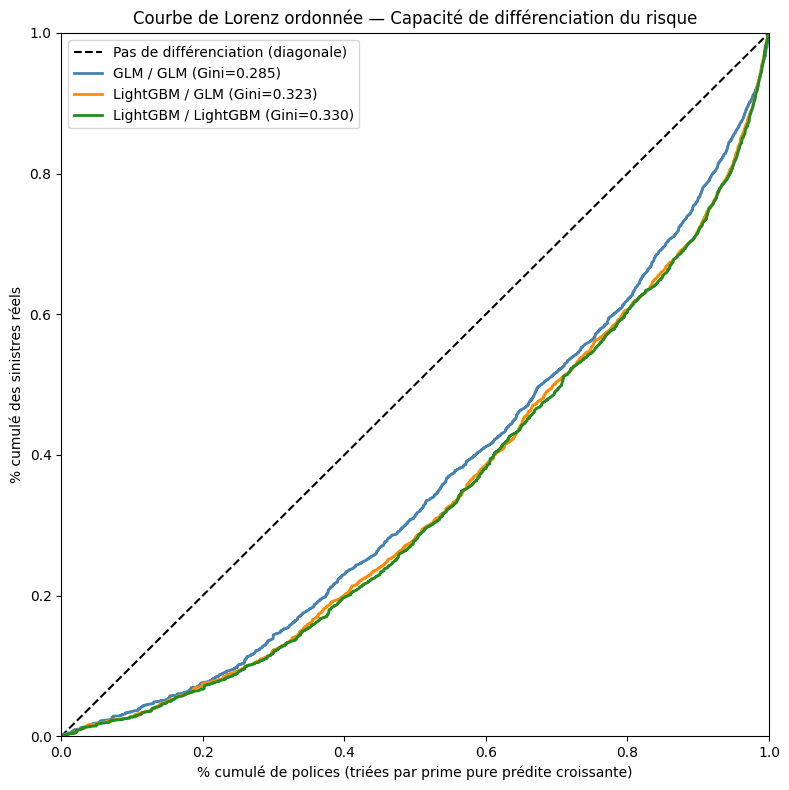

In [ ]:
# ============================================================
# BLOC 8 — VISUALISATION
# ============================================================
fig, ax = plt.subplots(figsize=(8, 8))

ax.plot([0, 1], [0, 1], 'k--', label='Pas de différenciation (diagonale)')

colors = {'PP_GLM_GLM': 'steelblue', 'PP_LGBM_GLM': 'darkorange', 'PP_LGBM_LGBM': 'forestgreen'}
labels = {
    'PP_GLM_GLM':   f'GLM / GLM (Gini={results_gini["PP_GLM_GLM"][2]:.3f})',
    'PP_LGBM_GLM':  f'LightGBM / GLM (Gini={results_gini["PP_LGBM_GLM"][2]:.3f})',
    'PP_LGBM_LGBM': f'LightGBM / LightGBM (Gini={results_gini["PP_LGBM_LGBM"][2]:.3f})',
}

for col, (cum_pop, cum_losses, gini) in results_gini.items():
    ax.plot(cum_pop, cum_losses, color=colors[col], label=labels[col], linewidth=2)

ax.set_xlabel('% cumulé de polices (triées par prime pure prédite croissante)')
ax.set_ylabel('% cumulé des sinistres réels')
ax.set_title('Courbe de Lorenz ordonnée — Capacité de différenciation du risque')
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(f'{BASE}/models/lorenz_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# BLOC 9 — SAUVEGARDE DES RÉSULTATS FINAUX
# ============================================================
prime_pure.to_csv(f'{BASE}/data/prime_pure_test.csv', index=False)

summary = {
    'balance': {
        col: float(prime_pure[col].sum() / total_observed)
        for col in ['PP_GLM_GLM', 'PP_LGBM_GLM', 'PP_LGBM_LGBM']
    },
    'gini': {
        col: float(results_gini[col][2])
        for col in ['PP_GLM_GLM', 'PP_LGBM_GLM', 'PP_LGBM_LGBM']
    }
}
with open(f'{BASE}/models/module1_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Résultats finaux sauvegardés.")
print(json.dumps(summary, indent=2))

Résultats finaux sauvegardés.
{
  "balance": {
    "PP_GLM_GLM": 1.3439878118777853,
    "PP_LGBM_GLM": 1.3396590146571212,
    "PP_LGBM_LGBM": 1.3352884016843447
  },
  "gini": {
    "PP_GLM_GLM": 0.2845330475122062,
    "PP_LGBM_GLM": 0.32332808814134095,
    "PP_LGBM_LGBM": 0.3301355478783772
  }
}


In [ ]:
# ============================================================
# BLOC 10 — DIAGNOSTIC DE L'ÉCART DE BALANCE
# ============================================================
total_claimnb_test = y_test.sum()
n_claims_records = (prime_pure['ClaimAmount_total'] > 0).sum()

print(f"Somme de ClaimNb (table fréquence, test) : {total_claimnb_test:.0f}")
print(f"Nb de polices avec un enregistrement de sinistre (table sévérité) : {n_claims_records}")
print(f"Ratio : {total_claimnb_test / n_claims_records:.4f}")
# Si ce ratio est proche de 1.34, ça confirme l'origine du biais

Somme de ClaimNb (table fréquence, test) : 7156
Nb de polices avec un enregistrement de sinistre (table sévérité) : 4999
Ratio : 1.4315


In [ ]:
# ============================================================
# BLOC 11 — FACTEUR DE CHARGEMENT GLOBAL ET PRIME FINALE
# ============================================================
for col in ['PP_GLM_GLM', 'PP_LGBM_GLM', 'PP_LGBM_LGBM']:
    loading_factor = total_observed / prime_pure[col].sum()
    prime_pure[f'{col}_calibree'] = prime_pure[col] * loading_factor
    print(f"{col} : facteur de chargement = {loading_factor:.4f}")

# Vérification : la balance devient parfaite par construction
# (le Gini, lui, ne change PAS — la calibration est un simple
# rescaling multiplicatif, qui ne modifie pas l'ordre des polices)

PP_GLM_GLM : facteur de chargement = 0.7441
PP_LGBM_GLM : facteur de chargement = 0.7465
PP_LGBM_LGBM : facteur de chargement = 0.7489


In [15]:
# ============================================================
# EXPORT COMPLET POUR DÉPLOIEMENT LOCAL
# ============================================================

# Valeurs issues du script 3 (Bloc 3) — copiées en dur car calculées
# dans une session différente
rare_regions = ['R41', 'R25', 'R26', 'R23', 'R22', 'R83', 'R74', 'R94', 'R21', 'R42', 'R43']
rare_brands  = ['B11', 'B13', 'B14']

deployment_meta = {
    "feature_columns": X_cols,
    "glm_columns": glm_cols,
    "correction_lgb_sev": float(correction_lgb_sev),
    "loading_factor": {
        "PP_GLM_GLM":   float(total_observed / prime_pure['PP_GLM_GLM'].sum()),
        "PP_LGBM_GLM":  float(total_observed / prime_pure['PP_LGBM_GLM'].sum()),
        "PP_LGBM_LGBM": float(total_observed / prime_pure['PP_LGBM_LGBM'].sum()),
    },
    "rare_regions": rare_regions,
    "rare_brands": rare_brands,
    "champion": "PP_LGBM_GLM",
    "lib_versions": {
        "statsmodels": __import__('statsmodels').__version__,
        "lightgbm": lgb.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    }
}

with open(f'{BASE}/models/deployment_meta.json', 'w') as f:
    json.dump(deployment_meta, f, indent=2, default=str)

print(json.dumps(deployment_meta, indent=2, default=str))

{
  "feature_columns": [
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "Density",
    "Area_B",
    "Area_C",
    "Area_D",
    "Area_E",
    "Area_F",
    "VehBrand_B10",
    "VehBrand_B12",
    "VehBrand_B2",
    "VehBrand_B3",
    "VehBrand_B4",
    "VehBrand_B5",
    "VehBrand_B6",
    "VehBrand_Other",
    "VehGas_Regular",
    "Region_R11",
    "Region_R24",
    "Region_R31",
    "Region_R52",
    "Region_R53",
    "Region_R54",
    "Region_R72",
    "Region_R73",
    "Region_R82",
    "Region_R91",
    "Region_R93",
    "DrivAge_band_1.0",
    "DrivAge_band_2.0",
    "DrivAge_band_3.0",
    "DrivAge_band_4.0",
    "BonusMalus_band_1.0",
    "BonusMalus_band_2.0",
    "BonusMalus_band_3.0",
    "BonusMalus_band_4.0",
    "VehAge_band_1.0",
    "VehAge_band_2.0",
    "VehAge_band_3.0",
    "VehAge_band_4.0",
    "VehAge_band_5.0"
  ],
  "glm_columns": [
    "const",
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "Density",
    "Area_B",
   

In [16]:
# ============================================================
# DIAGNOSTIC — QUE CONTIENT LE DOSSIER models/ ?
# ============================================================
import os

models_dir = f'{BASE}/models'
print(f"Contenu de {models_dir} :")
for f in sorted(os.listdir(models_dir)):
    taille = os.path.getsize(os.path.join(models_dir, f))
    print(f"  {f:<30} {taille:>10} octets")

Contenu de /content/drive/MyDrive/siap/models :
  best_params.json                     1517 octets
  deployment_meta.json                 2293 octets
  glm_coefficients.json                4887 octets
  glm_columns.json                      681 octets
  glm_freq.pkl                    425247923 octets
  glm_sev.pkl                      16719777 octets
  lgb_freq.pkl                      6892745 octets
  lgb_sev.pkl                        117955 octets
  lorenz_curve.png                   132162 octets
  module1_summary.json                  272 octets
  xgb_freq.json                     4607097 octets
  xgb_sev.json                       202742 octets


In [17]:
from google.colab import files

fichiers_a_telecharger = [
    'lgb_freq.pkl',           # 6.9 Mo — fréquence (champion)
    'glm_coefficients.json',  # 4.9 Ko — sévérité (calcul manuel)
    'deployment_meta.json',   # 2.3 Ko — métadonnées
]

for fname in fichiers_a_telecharger:
    files.download(f'{BASE}/models/{fname}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>